In [35]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

Chargement du jeu de donnees et exploration

In [36]:
df=pd.read_csv("Advertising.csv")

df.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


La colonne Unnamed: 0 est un index sans valeur analytique, je l’ai supprimée.

In [37]:
df = df.drop(columns="Unnamed: 0")
df.shape

(200, 4)

le jeu de donnees contient 200 enregistrements ou lignes repartis sur 4 colonnes

In [38]:
df.info

<bound method DataFrame.info of         TV  radio  newspaper  sales
0    230.1   37.8       69.2   22.1
1     44.5   39.3       45.1   10.4
2     17.2   45.9       69.3    9.3
3    151.5   41.3       58.5   18.5
4    180.8   10.8       58.4   12.9
..     ...    ...        ...    ...
195   38.2    3.7       13.8    7.6
196   94.2    4.9        8.1    9.7
197  177.0    9.3        6.4   12.8
198  283.6   42.0       66.2   25.5
199  232.1    8.6        8.7   13.4

[200 rows x 4 columns]>

In [39]:
df.isnull().sum()

TV           0
radio        0
newspaper    0
sales        0
dtype: int64

In [40]:
df.isna().sum()

TV           0
radio        0
newspaper    0
sales        0
dtype: int64

analyse aucune valeur nulle

### statistique descriptive

In [41]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.0425,85.854236,0.7,74.375,149.75,218.825,296.4
radio,200.0,23.2640,14.846809,0.0,9.975,22.90,36.525,49.6
newspaper,200.0,30.5540,21.778621,0.3,12.750,25.75,45.100,114.0
sales,200.0,14.0225,5.217457,1.6,10.375,12.90,17.400,27.0


In [42]:
df.duplicated().sum()

np.int64(0)

### Exploration initiale

- **Taille et qualité** : le jeu de données contient 200 enregistrements et 4 variables après suppression de la colonne `Unnamed: 0`, qui n'est qu'un index sans valeur analytique. Aucune valeur manquante.
- **TV** : budget moyen le plus élevé (envion 147), médiane proche (149,75), donc une distribution plutôt symétrique. L'étendue est grande, de 0,7 à 296,4.
- **radio** : moyenne envrion 23,3 et médiane environ 22,9, distribution plutôt symétrique. Valeurs de 0 à 49,6.
- **newspaper** : moyenne environ 30,6 supérieure à la médiane (25,75), avec un maximum de 114 très éloigné du reste. Cela suggère quelques valeurs extrêmes, à vérifier avec notre boxplot.
- **sales** : moyenne  14,0 et médiane 12,9, avec des valeurs de 1,6 à 27,0.
- **Canal au budget moyen le plus élevé** : la TV, suivie du journal puis de la radio.

## visualisations

pairplot

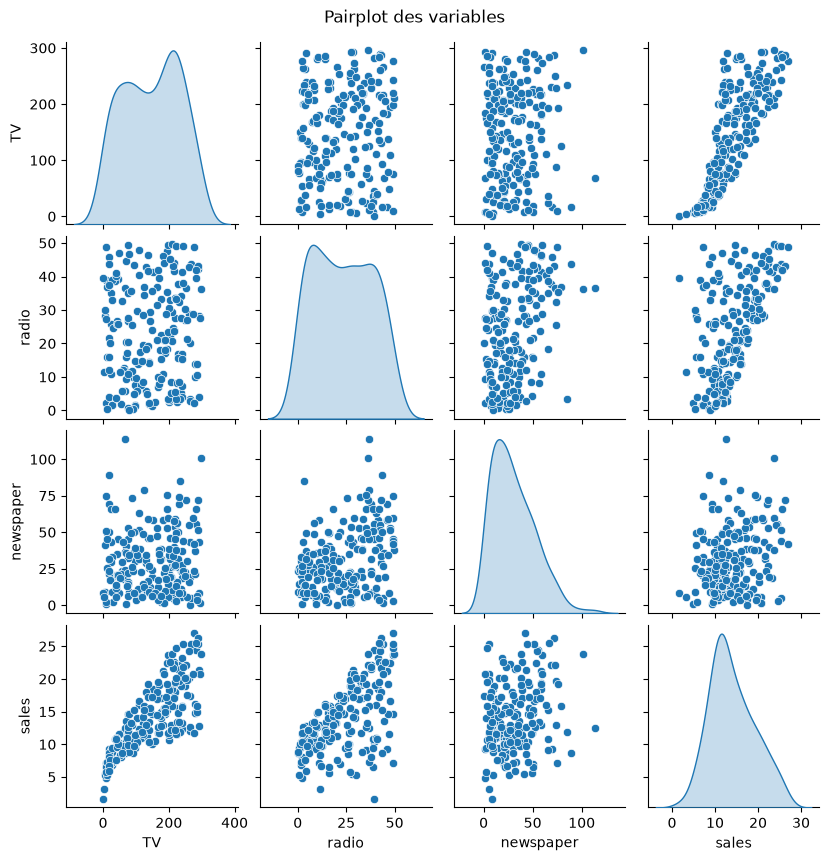

In [43]:
p=sns.pairplot(data=df,diag_kind="kde",kind="scatter",height=2.1)
p.figure.suptitle("Pairplot des variables", y=1.02) 
plt.show()

### Observations du pairplot

- **TV et sales** : relation linéaire positive nette. Quand le budget TV augmente, les ventes augmentent, et les points sont étroitement groupés autour d'une droite ascendante.
- **radio et sales** : relation positive mais plus dispersée qu'avec la TV. Les ventes tendent à augmenter avec le budget radio, mais avec davantage de variations autour de la tendance.
- **newspaper et sales** : points éparpillés, sans alignement net. La relation semble faible, voire absente : un budget élevé en journaux ne s'accompagne pas systématiquement de ventes plus élevées.
- **newspaper (distribution)** : courbe asymétrique, étalée vers les valeurs élevées, ce qui confirme les valeurs extrêmes repérées avec `describe()` (maximum de 114).
- **Hypothèse** : la TV serait le canal le plus influent sur les ventes, suivie de la radio, et le journal serait le moins utile.

# Carte thermique de la matrice de corrélation

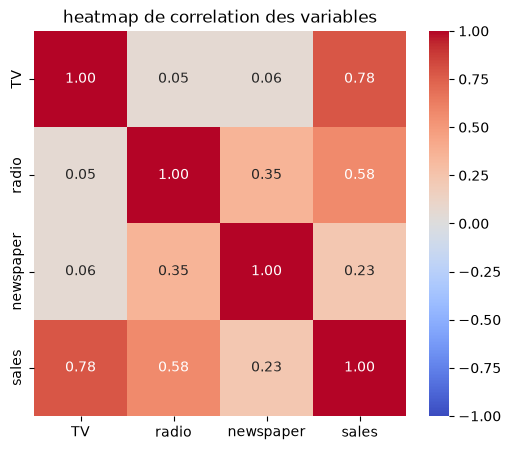

In [53]:
plt.figure(figsize=(6, 5))
df_corr= df.corr()
df_corr.T
sns.heatmap(df_corr,annot=True, fmt=".2f", cmap="coolwarm",vmin=-1,vmax=1)
plt.title("heatmap de correlation des variables")
plt.show()


In [54]:
df_corr

,TV,radio,newspaper,sales
TV,1.000000,0.054809,0.056648,0.782224
radio,0.054809,1.000000,0.354104,0.576223
newspaper,0.056648,0.354104,1.000000,0.228299
sales,0.782224,0.576223,0.228299,1.000000


### Observations de la heatmap de corrélation
- **TV et sales** : corrélation de 0,78, forte et positive. Les ventes tendent à augmenter quand le budget TV augmente.
- **radio et sales** : corrélation de 0,58, modérée et positive. Le lien est réel mais moins fort que pour la TV.
- **newspaper et sales** : corrélation de 0,23, faible. Ce lien pourrait s'expliquer en partie par la corrélation du journal avec la radio (0,35) ; les coefficients de la régression permettront de le vérifier.
- **Relations entre canaux** : la TV est indépendante des deux autres (≈ 0,05) ; radio et newspaper sont légèrement liées (0,35), ce qui confirme l'impression du pairplot.
- **Cohérence avec le pairplot** : l'ordre TV > radio > newspaper observé visuellement est confirmé par les valeurs chiffrées.
- **Limites** : une corrélation mesure un lien linéaire, pas une causalité.

# nuage des points

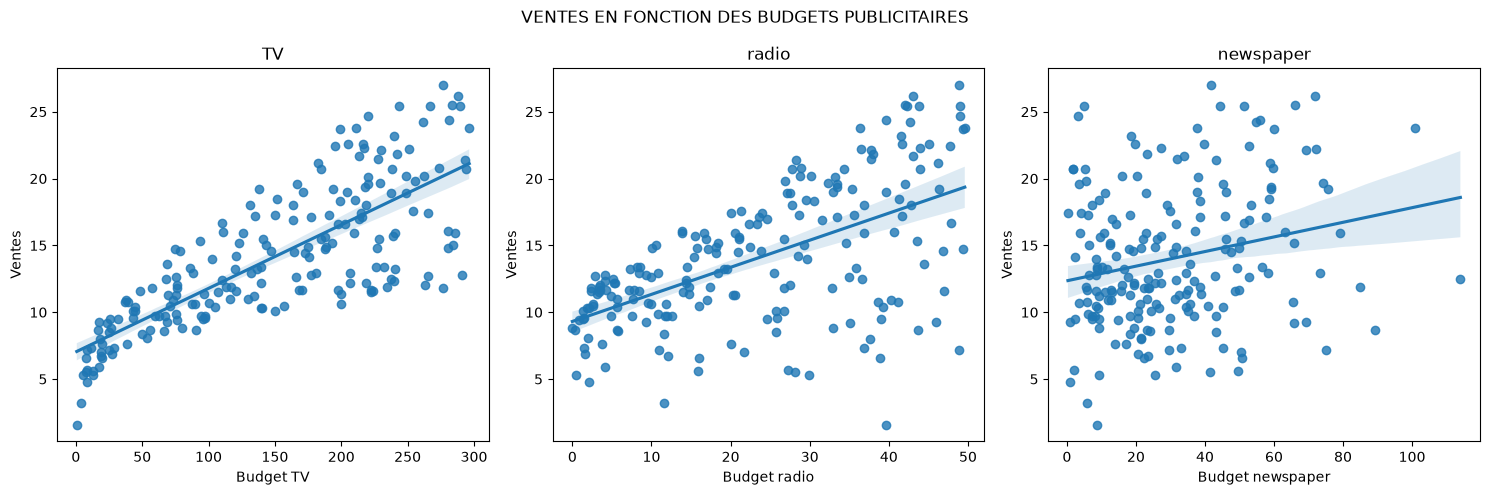

In [66]:
fig,axes=plt.subplots(1,3,figsize=(15,5))

for ax,var in zip(axes,['TV','radio','newspaper']):
    sns.regplot(data=df,y="sales" ,x=var,ax=ax)
    ax.set_title(var)
    ax.set_xlabel(f"Budget {var}") 
    ax.set_ylabel("Ventes")
plt.suptitle('VENTES EN FONCTION DES BUDGETS PUBLICITAIRES')
plt.tight_layout()
plt.show()

### Observations des nuages de points
- **TV** : pente raide, dispersion point alinges 
- **radio** : pente moyennement plate plus faible, dispersion elevees des points
- **newspaper** : pente plate, dispersion .complets
- **Conclusion provisoire** : le budget publicitaires de la TV est la preuve de l augmentaire des ventes